# California Housing Data

This notebook explores the housing data, prepares a few features, and checks selected numeric distributions.


In [317]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df_original = pd.read_csv('data/housing.csv')
df = pd.read_csv('data/housing.csv')

# Part 1: Exploratory Data Analysis (EDA)

Inspect the dataset, check missing values, and review feature distributions.


## Load and inspect the data

Load the CSV into a DataFrame, then preview its rows, columns, and category counts.


In [318]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [319]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [320]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

## Check and handle missing bedroom values

Count missing values, inspect rows with missing `total_bedrooms`, and remove those rows before calculations that use the column.

In [321]:
df.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [322]:
df[df['total_bedrooms'].isna()].describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,207.000000,207.000000,207.000000,207.000000,0.0,207.000000,207.000000,207.000000,207.000000
mean,-119.472560,35.497633,29.270531,2562.603865,NaN,1477.772947,510.024155,3.822244,206007.280193
std,2.001424,2.097298,11.964927,1787.269789,NaN,1057.448212,386.120704,1.955595,111638.214545
min,-124.130000,32.660000,4.000000,154.000000,NaN,37.000000,16.000000,0.852700,45800.000000
25%,-121.810000,33.970000,19.000000,1307.500000,NaN,781.000000,258.000000,2.564150,128750.000000
50%,-118.490000,34.200000,30.000000,2155.000000,NaN,1217.000000,427.000000,3.411500,175000.000000
75%,-117.985000,37.495000,38.000000,3465.000000,NaN,1889.500000,628.000000,4.615750,267700.000000
max,-114.590000,40.920000,52.000000,11709.000000,NaN,7604.000000,3589.000000,15.000100,500001.000000


In [323]:
df = df.dropna(subset=['total_bedrooms'])

## Prepare the categorical feature

Convert `ocean_proximity` into indicator columns so the categories are represented numerically.

In [324]:
df = pd.get_dummies(df,columns=["ocean_proximity"], dtype=int)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0


## Review numeric summaries

Use descriptive statistics to check the ranges and typical values in the dataset.

In [325]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,2636.504233,537.870553,1424.946949,499.433465,3.871162,206864.413155,0.442128,0.317917,0.000245,0.111095,0.128615
std,2.003578,2.136348,12.591805,2185.269567,421.385070,1133.208490,382.299226,1.899291,115435.667099,0.496652,0.465678,0.015641,0.314257,0.334782
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-121.800000,33.930000,18.000000,1450.000000,296.000000,787.000000,280.000000,2.563700,119500.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.536500,179700.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,-118.010000,37.720000,37.000000,3143.000000,647.000000,1722.000000,604.000000,4.744000,264700.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Inspect distributions before transformation

Use boxplots and histograms to look at house value, total rooms, and total bedrooms.

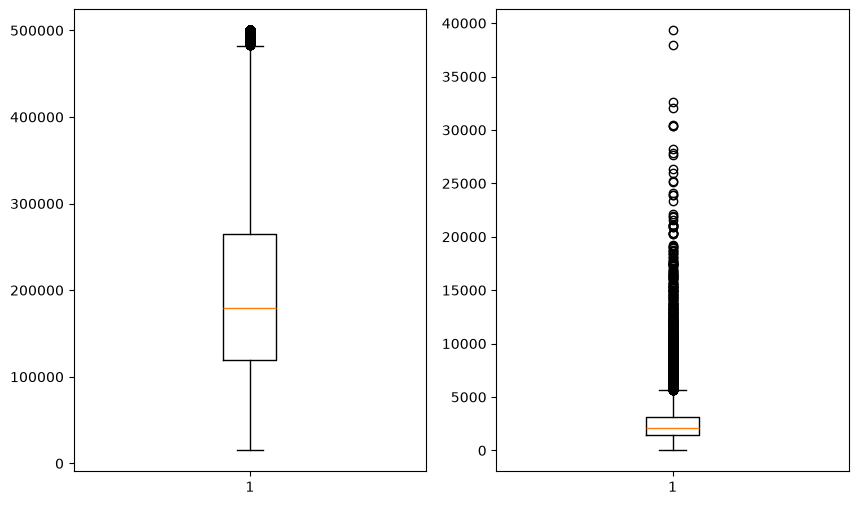

In [326]:
plt.figure(figsize=(10, 6))
plt.subplot(1, 2, 1)
plt.boxplot(df['median_house_value'])
plt.subplot(1, 2, 2)
plt.boxplot(df['total_rooms']);



plt.show()


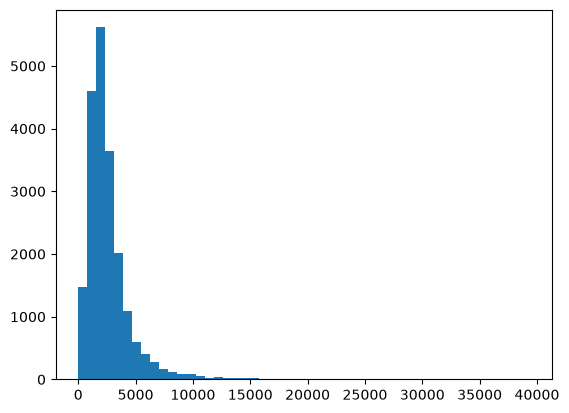

In [327]:
plt.hist(df['total_rooms'], bins=50)
plt.show()

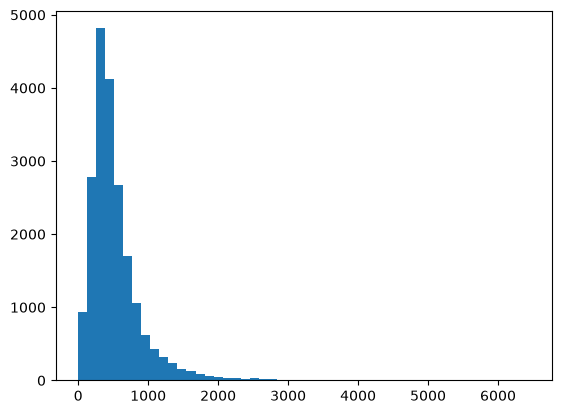

In [328]:
plt.hist(df['total_bedrooms'], bins=50)
plt.show()

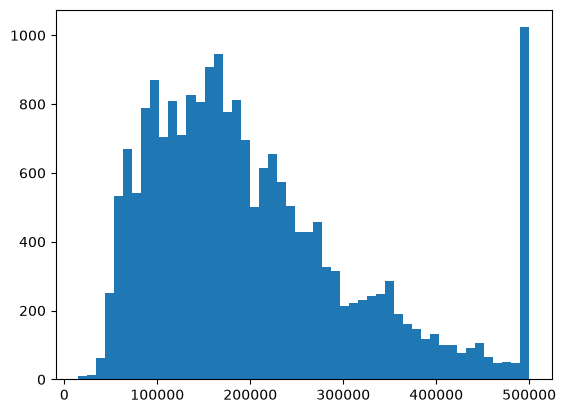

In [329]:
plt.hist(df['median_house_value'], bins=50)
plt.show()

In [330]:
(df['median_house_value'] == df['median_house_value'].max()).mean()

np.float64(0.04688494102677042)

In [331]:
df['median_house_value'].value_counts().head(10)

median_house_value
500001.0    958
137500.0    119
162500.0    116
112500.0    103
187500.0     92
225000.0     91
350000.0     79
87500.0      77
275000.0     65
150000.0     64
Name: count, dtype: int64

It seems that the maximum house value of 500,001 is a cap in the dataset. This may affect the distribution and should be considered in any modeling.

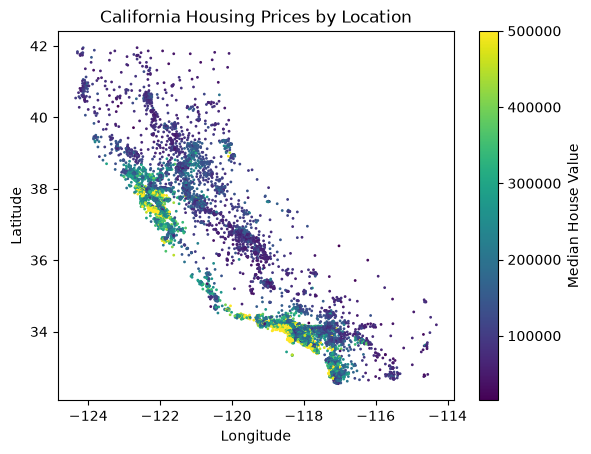

In [332]:
plt.scatter(df['longitude'], df['latitude'], c=df['median_house_value'], cmap='viridis', s=1)
plt.colorbar(label='Median House Value')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('California Housing Prices by Location')
plt.show()

![title](california_map.png)

As we can see from the plot, and from the map, the highest house values are concentrated in the San Francisco Bay Area and along the coast (near the big cities). The lowest values are found in the Central Valley and inland areas.

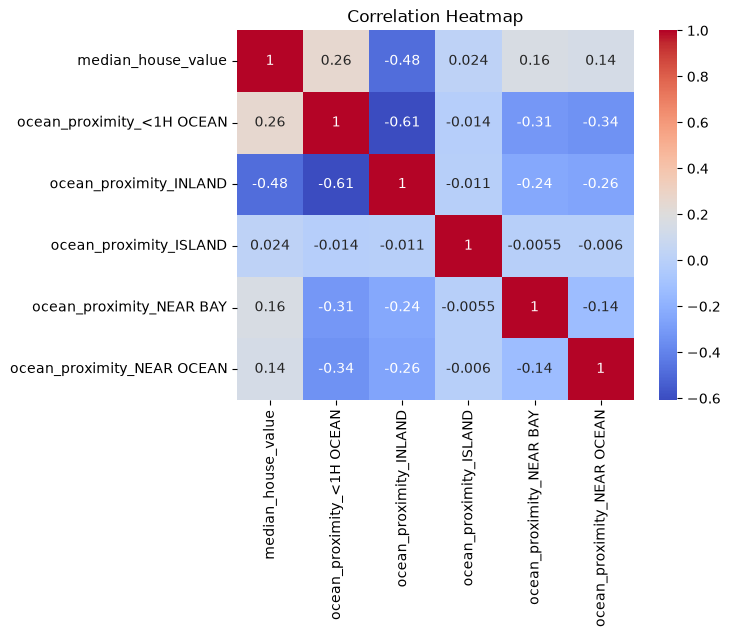

In [333]:
sns.heatmap(df[['median_house_value', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# Part 2: Feature Engineering

Create household-level ratios and transform the room and bedroom counts.


In [334]:
df['rooms_per_household'] = (
    df['total_rooms'] / df['households']
)

df['bedrooms_per_room'] = (
    df['total_bedrooms'] / df['total_rooms']
)

df['population_per_household'] = (
    df['population'] / df['households']
)

## Reduce skew in room and bedroom counts

Apply `log1p`, which calculates `log(1 + x)`, to the room and bedroom counts.

In [335]:
df['total_rooms'] = np.log1p(df['total_rooms'])


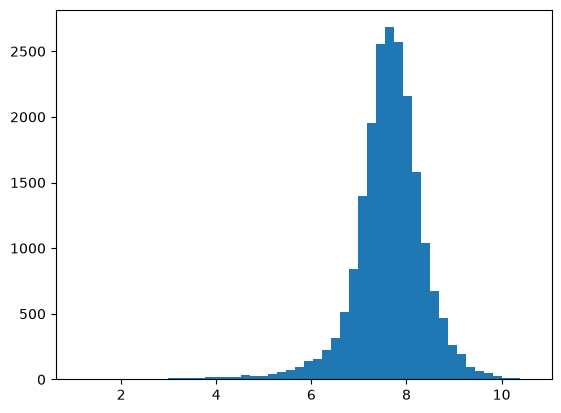

In [336]:
plt.hist(df['total_rooms'], bins=50)
plt.show()

In [337]:
df['total_bedrooms'] = np.log1p(df['total_bedrooms'])

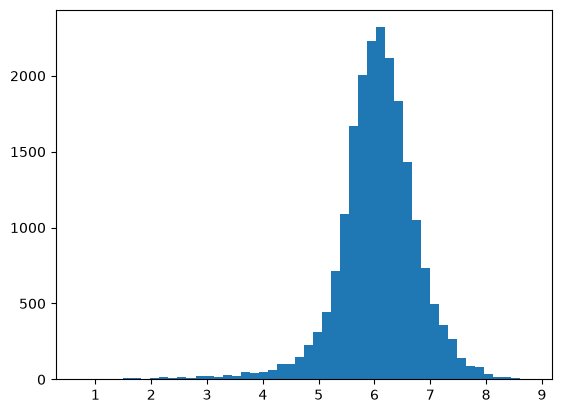

In [338]:
plt.hist(df['total_bedrooms'], bins=50)
plt.show()

In [339]:
df['latitude_near_ocean'] = (
    df['latitude'] *
    df['ocean_proximity_NEAR OCEAN']
)

df['longitude_inland'] = (
    df['longitude'] *
    df['ocean_proximity_INLAND']
)

df['latitude_near_bay'] = (
    df['latitude'] *
    df['ocean_proximity_NEAR BAY']
)
df['income_near_ocean'] = (
    df['median_income'] *
    df['ocean_proximity_NEAR OCEAN']
)

df['income_inland'] = (
    df['median_income'] *
    df['ocean_proximity_INLAND']
)

df['latitude_longitude'] = (
    df['latitude'] * df['longitude']
)

## Review the transformed data

Check the histograms and descriptive statistics after the transformations.

In [340]:
df.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_<1H OCEAN,...,ocean_proximity_NEAR OCEAN,rooms_per_household,bedrooms_per_room,population_per_household,latitude_near_ocean,longitude_inland,latitude_near_bay,income_near_ocean,income_inland,latitude_longitude
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,...,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,7.629543,6.054708,1424.946949,499.433465,3.871162,206864.413155,0.442128,...,0.128615,5.431344,0.213039,3.071533,4.467596,-38.065195,4.199528,0.515282,1.020628,-4264.646279
std,2.003578,2.136348,12.591805,0.750260,0.726728,1133.208490,382.299226,1.899291,115435.667099,0.496652,...,0.334782,2.482946,0.057983,10.438269,11.657591,55.767430,11.879491,1.523686,1.700451,323.948866
min,-124.350000,32.540000,1.000000,1.098612,0.693147,3.000000,1.000000,0.499900,14999.000000,0.000000,...,0.000000,0.846154,0.100000,0.692308,0.000000,-123.730000,0.000000,0.000000,0.000000,-5207.673000
25%,-121.800000,33.930000,18.000000,7.280008,5.693732,787.000000,280.000000,2.563700,119500.000000,0.000000,...,0.000000,4.441441,0.175427,2.429032,0.000000,-117.660000,0.000000,0.000000,0.000000,-4601.363200
50%,-118.490000,34.260000,29.000000,7.662938,6.077642,1166.000000,409.000000,3.536500,179700.000000,0.000000,...,0.000000,5.230769,0.203162,2.817582,0.000000,0.000000,0.000000,0.000000,0.000000,-4060.373500
75%,-118.010000,37.720000,37.000000,8.053251,6.473891,1722.000000,604.000000,4.744000,264700.000000,1.000000,...,0.000000,6.052381,0.239821,3.281513,0.000000,0.000000,0.000000,0.000000,2.080700,-4004.280600
max,-114.310000,41.950000,52.000000,10.579514,8.771215,35682.000000,6082.000000,15.000100,500001.000000,1.000000,...,1.000000,141.909091,1.000000,1243.333333,41.950000,-0.000000,38.340000,15.000100,15.000100,-3753.968400


In [341]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [342]:
wide_features = [
    'longitude',
    'latitude',
    'housing_median_age',
    'population',
    'households',
    'median_income',
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household',

    # Categorical features
    'ocean_proximity_<1H OCEAN',
    'ocean_proximity_INLAND',
    'ocean_proximity_ISLAND',
    'ocean_proximity_NEAR BAY',
    'ocean_proximity_NEAR OCEAN'
]

deep_features = [
    'longitude',
    'latitude',
    'housing_median_age',
    'population',
    'households',
    'median_income',
    'total_rooms',
    'total_bedrooms',
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household',

    # Categorical features
    'ocean_proximity_<1H OCEAN',
    'ocean_proximity_INLAND',
    'ocean_proximity_ISLAND',
    'ocean_proximity_NEAR BAY',
    'ocean_proximity_NEAR OCEAN'
]

In [343]:
wide_features += [
    'latitude_near_ocean',
    'longitude_inland',
    'latitude_near_bay',
    'income_near_ocean',
    'income_inland',
    'latitude_longitude'
]

In [344]:
from sklearn.preprocessing import StandardScaler

numerical_features = [
    'longitude',
    'latitude',
    'housing_median_age',
    'population',
    'households',
    'median_income',
    'total_rooms',
    'total_bedrooms',
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household'
]

categorical_features = [
    'ocean_proximity_<1H OCEAN',
    'ocean_proximity_INLAND',
    'ocean_proximity_ISLAND',
    'ocean_proximity_NEAR BAY',
    'ocean_proximity_NEAR OCEAN'
]

scaler = StandardScaler()
X_train[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

X_val[numerical_features] = scaler.transform(
    X_val[numerical_features]
)

In [345]:
from torch.utils.data import TensorDataset, DataLoader
import torch
import torch.nn as nn
X_train_wide = X_train[wide_features]
X_train_deep = X_train[deep_features]

X_train_wide_tensor = torch.tensor(X_train_wide.values, dtype=torch.float32)
X_train_deep_tensor = torch.tensor(X_train_deep.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

train_data_wd = TensorDataset(X_train_wide_tensor, X_train_deep_tensor, y_train_tensor)
train_loader_wd = DataLoader(train_data_wd, batch_size=32, shuffle=True)

In [364]:

import importlib
import models.model

importlib.reload(models.model)
from models.model import Wide_and_Deep
model = Wide_and_Deep(
    wide_X = len(wide_features),
    deep_X = len(deep_features),
).to('mps')

In [362]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

In [373]:
from models.train import train
importlib.reload(models.train)

train(model,optimizer,(nn.MSELoss()),train_loader_wd,n_epochs=10)

Epoch 1/10, Loss: 55715037312.2505
Epoch 2/10, Loss: 55715059259.1155
Epoch 3/10, Loss: 55717026513.4090
Epoch 4/10, Loss: 55711763502.0900
Epoch 5/10, Loss: 55711138890.1448
Epoch 6/10, Loss: 55716217104.5323
Epoch 7/10, Loss: 55716580550.3875
Epoch 8/10, Loss: 55718992889.9883
Epoch 9/10, Loss: 55709802387.7887
Epoch 10/10, Loss: 55708968306.7241


In [455]:
importlib.reload(models.train)
from models.train import evaluate
eval_data_loader_wd = DataLoader(
    TensorDataset(
        torch.tensor(X_val[wide_features].values, dtype=torch.float32),
        torch.tensor(X_val[deep_features].values, dtype=torch.float32),
        torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
    ),
    batch_size=32,
    shuffle=False
)
mse = evaluate(model,eval_data_loader_wd,nn.MSELoss()).item()
rmse = np.sqrt(mse)
print(f"Validation RMSE: {rmse:.2f}")

Validation RMSE: 237869.22
